# CNN architecture experiments 5–8

Experiments 1–4 in `02_Preprocessing.ipynb` compared the original image CNN with different dropout and weight-decay settings. Here we compare four architecture changes in the requested order. Each change is compared with the original CNN twice: (1) no dropout or weight decay, and (2) dropout 0.5 plus AdamW weight decay 1e-4.

All models use image bands only, the same horizontal/vertical training augmentation, AdamW learning rate 0.001, batch size 32, up to 40 epochs and patience 6. A single shuffled stratified 5-fold split with seed 42 is reused for all groups; model/training seed 42 is reset before every fold. Pixel statistics are fitted on the training fold only. These cross-validation settings follow `04_Cross_Validation.ipynb`, so results are separate from the single-holdout scores in 02.

The validation fold selects the best epoch and is also reported, which can make results optimistic. These folds share training data, and this run uses one split seed and one training seed per fold. Results are useful for exploration; repeated seeds and nested CV or an untouched test set are needed for a stronger final assessment. Different architectures can consume random numbers differently despite a shared seed.


In [1]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset, TensorDataset

train = pd.read_json("data/train.json")
band1 = np.stack(train["band_1"]).reshape(-1, 75, 75)
band2 = np.stack(train["band_2"]).reshape(-1, 75, 75)
X = np.stack([band1, band2], axis=1).astype(np.float32)
y = train["is_iceberg"].to_numpy(dtype=np.int64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))
print("X:", X.shape, "| y:", y.shape, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


X: (1604, 2, 75, 75) | y: (1604,) | device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU


In [2]:
class AugmentedImages(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        image = self.images[i].clone()
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])
        return image, self.labels[i]


class IcebergCNN(nn.Module):
    def __init__(self, architecture="original", dropout=0.0):
        super().__init__()
        if architecture not in ("original", "gap", "small_hidden", "third_block", "batch_norm"):
            raise ValueError("Unknown architecture")
        use_bn = architecture == "batch_norm"
        layers = [nn.Conv2d(2, 16, 3, padding=1)]
        if use_bn:
            layers.append(nn.BatchNorm2d(16))
        layers += [nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1)]
        if use_bn:
            layers.append(nn.BatchNorm2d(32))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]
        if architecture == "third_block":
            # 75 -> 37 -> 18 -> 9; third block increases channels 32 -> 64.
            layers += [nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        if architecture == "gap":
            # Average each of the 32 feature maps to one number.
            self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                            nn.Dropout(dropout) if dropout else nn.Identity(),
                                            nn.Linear(32, 2))
        else:
            in_features = 64 * 9 * 9 if architecture == "third_block" else 32 * 18 * 18
            hidden = 16 if architecture == "small_hidden" else 64
            self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_features, hidden), nn.ReLU(),
                                            nn.Dropout(dropout) if dropout else nn.Identity(),
                                            nn.Linear(hidden, 2))

    def forward(self, images):
        return self.classifier(self.features(images))


In [3]:
def evaluate_fold(architecture, dropout, weight_decay, train_idx, val_idx):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    tr = AugmentedImages(X_tr, y_tr)
    va = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    tr_loader = DataLoader(tr, batch_size=32, shuffle=True)
    va_loader = DataLoader(va, batch_size=32, shuffle=False)
    model = IcebergCNN(architecture, dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0

    for epoch in range(40):
        model.train()  # BatchNorm updates running statistics only during training.
        for images, labels in tr_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
        model.eval()  # Validation uses BatchNorm training statistics.
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in va_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(va)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for images, _ in va_loader:
            probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probs = np.asarray(probs)
    return {"best_epoch": best_epoch, "log_loss": log_loss(y_va, probs, labels=[0, 1]),
            "accuracy": float(np.mean((probs >= 0.5) == y_va)),
            "parameters": sum(p.numel() for p in model.parameters())}


def run_architecture(architecture):
    records = []
    for setting, dropout, weight_decay in (("basic", 0.0, 0.0), ("combined", 0.5, 1e-4)):
        print(f"\n{architecture} | {setting}", flush=True)
        for fold, (tr, va) in enumerate(folds, 1):
            result = evaluate_fold(architecture, dropout, weight_decay, tr, va)
            records.append({"architecture": architecture, "setting": setting, "fold": fold, **result})
            print(f"  Fold {fold}: epoch {result['best_epoch']}, "
                  f"log loss {result['log_loss']:.6f}, accuracy {result['accuracy']:.4%}, "
                  f"parameters {result['parameters']}", flush=True)
    return pd.DataFrame(records)


def show_summary(frame):
    return frame.groupby(["architecture", "setting"], sort=False).agg(
        mean_log_loss=("log_loss", "mean"), std_fold_log_loss=("log_loss", "std"),
        mean_accuracy=("accuracy", "mean"), parameters=("parameters", "first"))


## Matched original CNN reference

Train the reference once per regularization setting; all four changes use the same folds for comparison.


In [4]:
reference_results = run_architecture("original")
print(show_summary(reference_results).to_string())



original | basic
  Fold 1: epoch 8, log loss 0.354477, accuracy 85.6698%, parameters 668690
  Fold 2: epoch 17, log loss 0.317469, accuracy 85.9813%, parameters 668690
  Fold 3: epoch 21, log loss 0.335448, accuracy 84.1121%, parameters 668690
  Fold 4: epoch 20, log loss 0.260292, accuracy 90.3427%, parameters 668690
  Fold 5: epoch 13, log loss 0.281170, accuracy 86.8750%, parameters 668690

original | combined
  Fold 1: epoch 21, log loss 0.312426, accuracy 86.6044%, parameters 668690
  Fold 2: epoch 24, log loss 0.306361, accuracy 87.5389%, parameters 668690
  Fold 3: epoch 18, log loss 0.371052, accuracy 83.1776%, parameters 668690
  Fold 4: epoch 21, log loss 0.244885, accuracy 90.0312%, parameters 668690
  Fold 5: epoch 13, log loss 0.278511, accuracy 87.8125%, parameters 668690
                       mean_log_loss  std_fold_log_loss  mean_accuracy  parameters
architecture setting                                                              
original     basic          0.309771

## Experiment 5. Global Average Pooling

Replace Flatten and its large hidden layer with average pooling over each feature map, followed by a 32-to-2 classifier. This tests a large reduction in parameters.


In [5]:
results_5 = run_architecture("gap")
print(show_summary(pd.concat([reference_results, results_5], ignore_index=True)).to_string())



gap | basic
  Fold 1: epoch 38, log loss 0.450188, accuracy 78.5047%, parameters 5010
  Fold 2: epoch 40, log loss 0.474104, accuracy 74.4548%, parameters 5010
  Fold 3: epoch 40, log loss 0.482489, accuracy 73.2087%, parameters 5010
  Fold 4: epoch 37, log loss 0.469190, accuracy 73.5202%, parameters 5010
  Fold 5: epoch 36, log loss 0.434979, accuracy 78.1250%, parameters 5010

gap | combined
  Fold 1: epoch 40, log loss 0.469684, accuracy 76.0125%, parameters 5010
  Fold 2: epoch 38, log loss 0.479381, accuracy 72.2741%, parameters 5010
  Fold 3: epoch 40, log loss 0.485399, accuracy 71.3396%, parameters 5010
  Fold 4: epoch 40, log loss 0.472038, accuracy 71.9626%, parameters 5010
  Fold 5: epoch 39, log loss 0.454518, accuracy 73.7500%, parameters 5010
                       mean_log_loss  std_fold_log_loss  mean_accuracy  parameters
architecture setting                                                              
original     basic          0.309771           0.038676       0.8

## Experiment 6. Smaller hidden layer

Keep Flatten, and reduce the hidden layer from 64 to 16 units. This isolates a reduction in classifier capacity.


In [6]:
results_6 = run_architecture("small_hidden")
print(show_summary(pd.concat([reference_results, results_6], ignore_index=True)).to_string())



small_hidden | basic
  Fold 1: epoch 18, log loss 0.311784, accuracy 86.6044%, parameters 170882
  Fold 2: epoch 19, log loss 0.306442, accuracy 89.0966%, parameters 170882
  Fold 3: epoch 11, log loss 0.367946, accuracy 85.9813%, parameters 170882
  Fold 4: epoch 13, log loss 0.282928, accuracy 86.2928%, parameters 170882
  Fold 5: epoch 13, log loss 0.295924, accuracy 85.3125%, parameters 170882

small_hidden | combined
  Fold 1: epoch 23, log loss 0.402607, accuracy 81.9315%, parameters 170882
  Fold 2: epoch 15, log loss 0.399331, accuracy 80.6854%, parameters 170882
  Fold 3: epoch 19, log loss 0.384036, accuracy 81.9315%, parameters 170882
  Fold 4: epoch 36, log loss 0.288050, accuracy 88.1620%, parameters 170882
  Fold 5: epoch 19, log loss 0.298970, accuracy 88.4375%, parameters 170882
                       mean_log_loss  std_fold_log_loss  mean_accuracy  parameters
architecture setting                                                              
original     basic         

## Experiment 7. Third convolution block

Add a third 32-to-64 convolution, ReLU and pooling block, then adjust the classifier input to 64 × 9 × 9. This tests additional feature extraction.


In [ ]:
results_7 = run_architecture("third_block")
print(show_summary(pd.concat([reference_results, results_7], ignore_index=True)).to_string())



third_block | basic
  Fold 1: epoch 14, log loss 0.281731, accuracy 89.4081%, parameters 355410
  Fold 2: epoch 29, log loss 0.257283, accuracy 90.3427%, parameters 355410
  Fold 3: epoch 18, log loss 0.308166, accuracy 85.3583%, parameters 355410
  Fold 4: epoch 24, log loss 0.194258, accuracy 91.5888%, parameters 355410
  Fold 5: epoch 12, log loss 0.270736, accuracy 89.0625%, parameters 355410

third_block | combined
  Fold 1: epoch 23, log loss 0.243717, accuracy 91.5888%, parameters 355410
  Fold 2: epoch 32, log loss 0.222183, accuracy 91.5888%, parameters 355410
  Fold 3: epoch 17, log loss 0.297617, accuracy 87.2274%, parameters 355410
  Fold 4: epoch 24, log loss 0.188324, accuracy 91.2773%, parameters 355410
  Fold 5: epoch 14, log loss 0.276179, accuracy 88.1250%, parameters 355410
                       mean_log_loss  std_fold_log_loss  mean_accuracy  parameters
architecture setting                                                              
original     basic          0

## Experiment 8. Batch normalization

Insert BatchNorm2d after each convolution and before ReLU. Running statistics are updated on training data and used during validation.


In [ ]:
results_8 = run_architecture("batch_norm")
print(show_summary(pd.concat([reference_results, results_8], ignore_index=True)).to_string())



batch_norm | basic
  Fold 1: epoch 25, log loss 0.268830, accuracy 87.5389%, parameters 668786
  Fold 2: epoch 12, log loss 0.297164, accuracy 86.6044%, parameters 668786
  Fold 3: epoch 32, log loss 0.376885, accuracy 83.8006%, parameters 668786
  Fold 4: epoch 34, log loss 0.203900, accuracy 90.6542%, parameters 668786
  Fold 5: epoch 24, log loss 0.263075, accuracy 88.7500%, parameters 668786

batch_norm | combined
  Fold 1: epoch 29, log loss 0.439734, accuracy 78.8162%, parameters 668786
  Fold 2: epoch 37, log loss 0.380610, accuracy 85.9813%, parameters 668786
  Fold 3: epoch 33, log loss 0.348367, accuracy 83.4891%, parameters 668786
  Fold 4: epoch 10, log loss 0.516587, accuracy 68.8474%, parameters 668786
  Fold 5: epoch 38, log loss 0.353205, accuracy 86.5625%, parameters 668786
                       mean_log_loss  std_fold_log_loss  mean_accuracy  parameters
architecture setting                                                              
original     basic          0.3

## Combined comparison

Means and fold standard deviations are descriptive. Negative paired loss change favors the changed architecture on this particular split.


In [ ]:
all_results = pd.concat([reference_results, results_5, results_6, results_7, results_8], ignore_index=True)
summary = show_summary(all_results).reset_index()
print("All fold results:")
print(all_results.to_string(index=False))
print("\nSummary:")
print(summary.to_string(index=False))
print("\nChange versus the original CNN (new minus original):")
for setting in ("basic", "combined"):
    base = summary[(summary.architecture == "original") & (summary.setting == setting)].iloc[0]
    for name in ("gap", "small_hidden", "third_block", "batch_norm"):
        row = summary[(summary.architecture == name) & (summary.setting == setting)].iloc[0]
        print(f"{setting} | {name}: loss {row.mean_log_loss - base.mean_log_loss:+.6f}, "
              f"accuracy {(row.mean_accuracy - base.mean_accuracy)*100:+.2f} pp")


All fold results:
architecture  setting  fold  best_epoch  log_loss  accuracy  parameters
    original    basic     1           8  0.354477  0.856698      668690
    original    basic     2          17  0.317469  0.859813      668690
    original    basic     3          21  0.335448  0.841121      668690
    original    basic     4          20  0.260292  0.903427      668690
    original    basic     5          19  0.291947  0.878125      668690
    original combined     1          21  0.312426  0.866044      668690
    original combined     2          24  0.306361  0.875389      668690
    original combined     3          18  0.371052  0.831776      668690
    original combined     4          21  0.244885  0.900312      668690
    original combined     5          19  0.291156  0.871875      668690
         gap    basic     1          38  0.450188  0.785047        5010
         gap    basic     2          40  0.474104  0.744548        5010
         gap    basic     3          40  0.482

## Observed GPU results (2026-10-31)

The outputs above were generated by running these cells sequentially in a separate GPU process. The saved outputs do not populate variables in a newly opened kernel; rerun the notebook to recreate them. The following values are mean scores across the five seed-42 folds; accuracy is measured at the checkpoint with the lowest validation loss.

| Model | Setting | Parameters | Mean log loss | Mean accuracy |
| --- | --- | ---: | ---: | ---: |
| Original | Basic | 668,690 | 0.3119 | 86.78% |
| Original | Combined | 668,690 | 0.3052 | 86.91% |
| 5. Global average pooling | Basic | 5,010 | 0.4618 | 75.56% |
| 5. Global average pooling | Combined | 5,010 | 0.4723 | 73.07% |
| 6. Hidden layer 16 | Basic | 170,882 | 0.3114 | 87.10% |
| 6. Hidden layer 16 | Combined | 170,882 | 0.3531 | 84.17% |
| 7. Third convolution block | Basic | 355,410 | 0.2624 | 89.15% |
| 7. Third convolution block | Combined | 355,410 | 0.2456 | 89.96% |
| 8. Batch normalization | Basic | 668,786 | 0.2820 | 87.47% |
| 8. Batch normalization | Combined | 668,786 | 0.4077 | 80.74% |

- Global average pooling greatly reduces parameters but has worse results in this run. Several of its best epochs reach or nearly reach the 40-epoch limit, so longer training may change the comparison.
- A 16-unit hidden layer performs close to the original under basic settings and uses fewer parameters; its combined-setting result is worse in this run.
- The third block has the lowest mean log loss here in both settings. Its extra pooling also changes the classifier's input size and reduces total parameters, so the result reflects the complete architecture change.
- Batch normalization improves mean log loss under basic settings but performs worse with the combined setting in this run. These observations are sensitive to this split, initialization and training choices; they do not establish a universal interaction.
- Validation folds select checkpoints and also inform model choice. Fold results are dependent, and just one split seed and one training seed were used. Repeat with additional split/training seeds and use nested CV or a held-out test set before claiming generalization.


## Candidate model: experiment 7 with dropout + weight decay

In the earlier seed-42 5-fold comparison, the third convolution block with dropout 0.5 and weight decay 1e-4 had the lowest observed mean validation log loss, 0.2456. This is the current candidate for further evaluation. The same validation folds selected the best epoch and informed model choice, so this value may be optimistic; it is not an unbiased final test result.

The following check uses two additional shuffled stratified split seeds, 123 and 2024, with the same image-only model, augmentation, optimizer, fold-specific training normalization, 40-epoch limit and patience 6. Each fold resets training seed 42. It records training and validation losses at every epoch. The earlier seed-42 run saved fold scores but not per-epoch histories, so loss curves below cover the two new seeds; its saved fold scores are included in the cross-seed chart. Folds and repeated splits overlap, and this candidate was selected using seed 42. Use nested CV or an untouched test set and repeat training seeds before a strong generalization claim.


In [ ]:
import copy
import random
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold


def evaluate_candidate_with_history(train_idx, val_idx):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    # Fit the channel statistics on the training fold only.
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    training = AugmentedImages(X_tr, y_tr)
    validation = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    train_loader = DataLoader(training, batch_size=32, shuffle=True)
    val_loader = DataLoader(validation, batch_size=32, shuffle=False)
    model = IcebergCNN("third_block", dropout=0.5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    train_losses, val_losses = [], []
    for epoch in range(40):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
        train_losses.append(train_loss_sum / len(training))
        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(validation)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probs = np.asarray(probs)
    return {"best_epoch": best_epoch, "log_loss": log_loss(y_va, probs, labels=[0, 1]),
            "accuracy": float(np.mean((probs >= 0.5) == y_va)),
            "train_losses": train_losses, "val_losses": val_losses}, probs


In [ ]:
candidate_results = []
candidate_histories = {}
candidate_oof = {}
for split_seed in (123, 2024):
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
    oof = np.empty(len(y), dtype=np.float32)
    for fold, (train_idx, val_idx) in enumerate(splitter.split(X, y), 1):
        assert len(np.intersect1d(train_idx, val_idx)) == 0
        result, probabilities = evaluate_candidate_with_history(train_idx, val_idx)
        candidate_histories[(split_seed, fold)] = result
        oof[val_idx] = probabilities
        candidate_results.append({"split_seed": split_seed, "fold": fold,
                                  "best_epoch": result["best_epoch"],
                                  "log_loss": result["log_loss"], "accuracy": result["accuracy"]})
        print(f"Seed {split_seed} | fold {fold}: epoch {result['best_epoch']}, "
              f"log loss {result['log_loss']:.6f}, accuracy {result['accuracy']:.4%}", flush=True)
    candidate_oof[split_seed] = oof
candidate_df = pd.DataFrame(candidate_results)
print("\nPer-fold results:")
print(candidate_df.to_string(index=False))
candidate_summary = candidate_df.groupby("split_seed").agg(
    mean_log_loss=("log_loss", "mean"), std_fold_log_loss=("log_loss", "std"),
    mean_accuracy=("accuracy", "mean"), std_fold_accuracy=("accuracy", "std"))
print("\nSummary (fold standard deviations are descriptive):")
print(candidate_summary.to_string())
for seed in (123, 2024):
    print(f"Seed {seed} pooled OOF log loss: {log_loss(y, candidate_oof[seed], labels=[0, 1]):.6f}")


Seed 123 | fold 1: epoch 17, log loss 0.267271, accuracy 89.7196%
Seed 123 | fold 2: epoch 28, log loss 0.252577, accuracy 89.0966%
Seed 123 | fold 3: epoch 31, log loss 0.282591, accuracy 87.2274%
Seed 123 | fold 4: epoch 18, log loss 0.256793, accuracy 89.4081%
Seed 123 | fold 5: epoch 23, log loss 0.203812, accuracy 90.9375%
Seed 2024 | fold 1: epoch 24, log loss 0.214403, accuracy 91.9003%
Seed 2024 | fold 2: epoch 19, log loss 0.241679, accuracy 89.7196%
Seed 2024 | fold 3: epoch 25, log loss 0.238155, accuracy 90.6542%
Seed 2024 | fold 4: epoch 23, log loss 0.289551, accuracy 86.6044%
Seed 2024 | fold 5: epoch 15, log loss 0.294108, accuracy 86.2500%

Per-fold results:
 split_seed  fold  best_epoch  log_loss  accuracy
        123     1          17  0.267271  0.897196
        123     2          28  0.252577  0.890966
        123     3          31  0.282591  0.872274
        123     4          18  0.256793  0.894081
        123     5          23  0.203812  0.909375
       2024     

The following cell restores the measured histories when the training cell is skipped. Run the setup and model-definition cells first, then this cell and the plotting cells.


In [ ]:
# Saved results from the GPU run shown above. Full-precision epoch histories are retained.
# If the training cell was run in this kernel, keep its newer values.
_saved_candidate_histories = {(123, 1): {'best_epoch': 17, 'log_loss': 0.26727133989334106, 'accuracy': 0.897196261682243, 'train_losses': [0.6580651191557559, 0.618046596611466, 0.5530936519614627, 0.48019870179571034, 0.4714175513593461, 0.42050147326031606, 0.4109160890824518, 0.36461624026948924, 0.3670311814532648, 0.33071790100166043, 0.3262042001438554, 0.35131472540222286, 0.29302743541850584, 0.2715634073211361, 0.27939752576435717, 0.24642952237734084, 0.26124716548369625, 0.2601128748544751, 0.25027926637161746, 0.22825600650337172, 0.2386272880869365, 0.23280139015994775, 0.2188588124834181], 'val_losses': [0.6118798638429969, 0.5691798301500695, 0.4958921051888822, 0.43590561722512605, 0.39869112672278445, 0.3932683287475641, 0.39282041068719786, 0.3766071387070501, 0.34113684719982573, 0.33197654109169666, 0.36631985119002874, 0.29748519382372823, 0.34416102570324925, 0.29453403827940283, 0.307396342941615, 0.30631652603874626, 0.267271318098652, 0.37965306853208214, 0.28256968986765246, 0.3033220652850617, 0.31449955963526743, 0.27595644924104956, 0.2835903705280518]}, (123, 2): {'best_epoch': 28, 'log_loss': 0.2525767385959625, 'accuracy': 0.8909657320872274, 'train_losses': [0.657726875804684, 0.6096207774530977, 0.5130390984326345, 0.4821642156884899, 0.49280547761210963, 0.40788711308387693, 0.40457574301925564, 0.35926892894696927, 0.3560959212231542, 0.37370820804582566, 0.32177166868399015, 0.3249723865060442, 0.2871501863885465, 0.29029187906187953, 0.2996806169301852, 0.2647554114844217, 0.3594181202685958, 0.26386012427874683, 0.24199569926452724, 0.24410116816533328, 0.21289367361730277, 0.25554538057102233, 0.21087065283920461, 0.1828868312359042, 0.18845751711885306, 0.17654570765264874, 0.1904274396931706, 0.17401579013116084, 0.19196662369502865, 0.1941855413373197, 0.156593049050324, 0.1679838259856123, 0.14278494094266894, 0.14341022147247545], 'val_losses': [0.6278008582807404, 0.5723546810239275, 0.7368080036553424, 0.4853262739644801, 0.43449729271349136, 0.392401556287837, 0.3815062252537716, 0.3834723570091052, 0.5169172624930461, 0.3377627961343369, 0.3468949397615334, 0.34733878545219377, 0.31279296337299023, 0.2909464090114178, 0.31508110050580573, 0.3134921493314822, 0.3222206155281743, 0.3037697787823103, 0.331996771596906, 0.2688291138800995, 0.28167774952908925, 0.26681430858345573, 0.2976260666503909, 0.2850012248149414, 0.25959499745529635, 0.3207511716169574, 0.28034523083041635, 0.2525766972802589, 0.26817222057846796, 0.27838873937493913, 0.32052476755181253, 0.2674620218366074, 0.28963490215788323, 0.2802807088952941]}, (123, 3): {'best_epoch': 31, 'log_loss': 0.2825908660888672, 'accuracy': 0.8722741433021807, 'train_losses': [0.6532345899175316, 0.6080062538036962, 0.5469293100519842, 0.47673862512838255, 0.4080637695728014, 0.40439728750257126, 0.36647697354050607, 0.3519056893751571, 0.3350930818104688, 0.3055019591668576, 0.32309755387941747, 0.30809516948375587, 0.2535878264012043, 0.2494544131813436, 0.23950155538130066, 0.22364480219729135, 0.21607772079285523, 0.2337075668421232, 0.22670394545733139, 0.23182921451157132, 0.18910089277880832, 0.17954161671438165, 0.17955244307508597, 0.18366554647753783, 0.15874088630486724, 0.29339667069359116, 0.19901240125170744, 0.18667191353830526, 0.16068935359171965, 0.1800291815123703, 0.19119637066372094, 0.18604603585978027, 0.15130475758112508, 0.1554709004175821, 0.17020764276501452, 0.13427563276452564, 0.18323704599172735], 'val_losses': [0.6411315425534114, 0.63051641544449, 0.49436218771979074, 0.47860195462206073, 0.41866987330891264, 0.4047257179783141, 0.40135420872786337, 0.37273347767714027, 0.36712011889876606, 0.3410132172694459, 0.4961698259520011, 0.3463551218264571, 0.3286885266363435, 0.38158421278742616, 0.35327278565023545, 0.3229380964861481, 0.3534047540474532, 0.40462755896963437, 0.31142235136477747, 0.317706734034874, 0.3084552687276561, 0.3303973465879387, 0.3239472565992599, 0.31910732379212187, 0.42940078030494144, 0.29402312125743735, 0.32332234590595754, 0.3110515280304668, 0.39439783660793604, 0.29686232101508764, 0.28259087314486875, 0.31940713729071096, 0.3539739628075811, 0.3427148330898671, 0.2912218069361749, 0.5302483032796984, 0.3218133557251309]}, (123, 4): {'best_epoch': 18, 'log_loss': 0.2567932903766632, 'accuracy': 0.8940809968847352, 'train_losses': [0.6548392953393242, 0.5598623055503039, 0.5079319929110289, 0.5337228765965252, 0.43628486281874956, 0.4108839189098017, 0.38723660542085964, 0.3956737823999216, 0.4587071607185532, 0.36644607400253054, 0.3388658208643331, 0.35214348691381336, 0.33291423572800816, 0.28685544536899793, 0.3150807932448963, 0.2860661677127691, 0.26689546761434707, 0.2858188164530036, 0.24619698683010444, 0.26706727418180376, 0.23624530585594505, 0.24487028369100783, 0.2355337253744864, 0.21617026391583594], 'val_losses': [0.6181140380485035, 0.6087240548891442, 0.5738530565645094, 0.42528944070279784, 0.45425665332149495, 0.36547965384625203, 0.37218324380500295, 0.535735492387096, 0.36167527380112174, 0.3173747403413707, 0.40846909745088616, 0.3207221441319056, 0.2959082167235862, 0.2963540988373701, 0.27728928517944806, 0.2646232718540895, 0.42942032314013007, 0.2567932833438722, 0.34739776798219324, 0.2635924662738992, 0.25763623158931964, 0.32073827252139026, 0.3246611570228599, 0.27534957202374455]}, (123, 5): {'best_epoch': 23, 'log_loss': 0.20381192862987518, 'accuracy': 0.909375, 'train_losses': [0.6727800900319655, 0.6035310624173126, 0.5379035990928935, 0.4702517495162762, 0.46036923934366103, 0.38848121663863044, 0.39598238143222725, 0.3979226171598999, 0.36490845708089453, 0.3615200513062819, 0.33651022784806484, 0.3640439562598168, 0.3103039517209537, 0.3151589031345748, 0.27607517162587414, 0.2939577981876064, 0.2456890014000237, 0.2664386849165705, 0.24740021065388143, 0.24436312902289387, 0.2315254794623024, 0.2311272311062085, 0.22749262119750738, 0.2134995485577628, 0.2036096602678299, 0.24900142323933658, 0.24265562197501042, 0.17962462526986903, 0.19348746946667586], 'val_losses': [0.6050025045871734, 0.582734489440918, 0.43690299689769746, 0.4162944585084915, 0.3796579897403717, 0.4114797204732895, 0.34690660834312437, 0.3620032608509064, 0.4006753176450729, 0.3090633198618889, 0.2739932909607887, 0.3552203804254532, 0.30058651715517043, 0.2903830587863922, 0.27753220647573473, 0.24752197265625, 0.2503469601273537, 0.24606776982545853, 0.23750499486923218, 0.24530154913663865, 0.21139595210552214, 0.33124660551548, 0.2038119062781334, 0.22257978543639184, 0.22787900567054747, 0.2260525643825531, 0.22665461003780366, 0.2273764818906784, 0.20894363299012184]}, (2024, 1): {'best_epoch': 24, 'log_loss': 0.2144031524658203, 'accuracy': 0.9190031152647975, 'train_losses': [0.6670945051212563, 0.6076584949868783, 0.5336095892816247, 0.47465847611473766, 0.4472801894855425, 0.4599412213473792, 0.42335338587419, 0.39294919517945237, 0.3778940446657402, 0.4623706831610584, 0.36195308894546163, 0.33217545939625376, 0.3169536579426433, 0.33289645190640343, 0.28390384266270574, 0.31415891421440517, 0.2529941495313416, 0.26194138018244156, 0.2523415167398594, 0.2657493623096963, 0.23630068048149555, 0.23784142989296517, 0.23987506828267224, 0.23235385814450815, 0.22325038580065673, 0.21189145342626886, 0.2043102330971721, 0.19528744564575323, 0.20281073380684855, 0.18123383930392872], 'val_losses': [0.6288825028410582, 0.5326202623430071, 0.474072563174729, 0.41551896443661607, 0.41851211747160394, 0.36894487739890425, 0.3840651259724213, 0.3334862165828671, 0.35994643061146187, 0.354606970899515, 0.3010999981808618, 0.3670921013734019, 0.2628347613727213, 0.2799406447917487, 0.2648227109921577, 0.25782466808847526, 0.254277994692994, 0.23111548451182717, 0.24751892883868779, 0.2595158625980988, 0.2688560259304561, 0.260588211797549, 0.23379988347073563, 0.21440315276442923, 0.30322792151263933, 0.23632826924955436, 0.24149373349728392, 0.23373242968046382, 0.2809889413113374, 0.24835362724038773]}, (2024, 2): {'best_epoch': 19, 'log_loss': 0.24167928099632263, 'accuracy': 0.897196261682243, 'train_losses': [0.6645890748417201, 0.597266768628698, 0.544000272314621, 0.46542349087824975, 0.42744524982508886, 0.44485059823036566, 0.39034859240287373, 0.34929578420898455, 0.3140900811362037, 0.33932324953592113, 0.30747021239944855, 0.3239365289871895, 0.27486706453659343, 0.3333327551884105, 0.25775618974296544, 0.25817917009186947, 0.23060459990289559, 0.23720621146876525, 0.2417598181605246, 0.2309388250275134, 0.2146664628597878, 0.21294761822861638, 0.2012864223689375, 0.2406000786708466, 0.1819880442114566], 'val_losses': [0.6119968415792114, 0.5554674021737226, 0.5250401348339806, 0.3971860268591349, 0.36767988589322453, 0.363952616061377, 0.3763645154850505, 0.3063972169690043, 0.303235979141476, 0.3358405669715917, 0.27413448591562817, 0.29382254408434544, 0.321768648643917, 0.29181319746737167, 0.29793531292718706, 0.28869228334256053, 0.25829698057334605, 0.2626725970810958, 0.24167927884644716, 0.294331623586562, 0.2527270588503042, 0.2775796871005653, 0.2953249206331289, 0.25501491506859614, 0.2646034625126774]}, (2024, 3): {'best_epoch': 25, 'log_loss': 0.2381552755832672, 'accuracy': 0.9065420560747663, 'train_losses': [0.6627581722552388, 0.593803440000708, 0.5333194144285013, 0.4691818960922729, 0.514268530571916, 0.4203257215088081, 0.41782009740964754, 0.4022494466250889, 0.3725413292623179, 0.32117814197265254, 0.30402955565012163, 0.2940410670134023, 0.2980629359477215, 0.27439940839843274, 0.28649417622797396, 0.270564313220123, 0.2940017623029829, 0.26256711963369617, 0.2574053635865752, 0.230925872747729, 0.2651663276244213, 0.2318280061499295, 0.21811420199281986, 0.21050610590148325, 0.2273007412720544, 0.21861039587761266, 0.19567650477587015, 0.19870690781904773, 0.18313684140506076, 0.19343343411956276, 0.1837601803609011], 'val_losses': [0.6306497463927462, 0.5735970234202448, 0.4671360122451901, 0.5286121970025178, 0.4279155935453849, 0.4644730213646577, 0.43423102057982826, 0.359316574821591, 0.37897400692615923, 0.3447803492858031, 0.3182696224744446, 0.31272195692745697, 0.28703260663142455, 0.32215172163793976, 0.2795959299784212, 0.29784329695122264, 0.2819017039095501, 0.308100878263931, 0.2998033696988661, 0.26832770382132487, 0.25831630761006913, 0.2784715164858976, 0.24387066980760044, 0.2953898993979362, 0.23815527883274162, 0.25706752809780037, 0.2517400924290452, 0.25756926180046297, 0.26661726702410854, 0.24057990433271056, 0.2511650024916153]}, (2024, 4): {'best_epoch': 23, 'log_loss': 0.28955063223838806, 'accuracy': 0.8660436137071651, 'train_losses': [0.6544513747223819, 0.6095201794467489, 0.5332605331927096, 0.4779187453880221, 0.4235232248960392, 0.4123160179387938, 0.3732393222773159, 0.35099720638985754, 0.32037063023120466, 0.32002882224080076, 0.2954483474412423, 0.24874486467015572, 0.2862300587990789, 0.26651285805348207, 0.22843919233335525, 0.23681913135937668, 0.2990824904231847, 0.22238605477450094, 0.21264396451372983, 0.21533887875168378, 0.21294324537877077, 0.2225353569721488, 0.1938060044963566, 0.20769216210399163, 0.20402281303379746, 0.165152979641935, 0.15559913236604292, 0.18292158799404198, 0.14511290766351034], 'val_losses': [0.6454258811808078, 0.5759368945505018, 0.4772499172115623, 0.46837636094969753, 0.4848700186173864, 0.3521015268991298, 0.3407478295382681, 0.3515545428727646, 0.3612916317312888, 0.35316066847783384, 0.3106712384201656, 0.4303325448080758, 0.30956736086313597, 0.29937813642240385, 0.2995971084755158, 0.34591100232623445, 0.2986129243797231, 0.3229522094176937, 0.3166052244162634, 0.3752277907552749, 0.3418617146408818, 0.3123485674367887, 0.28955065089965537, 0.29532129092379894, 0.2968172083762576, 0.31447008632796575, 0.31308856132988616, 0.3041118190295971, 0.32496416345935003]}, (2024, 5): {'best_epoch': 15, 'log_loss': 0.2941083312034607, 'accuracy': 0.8625, 'train_losses': [0.6619258729096885, 0.6215928169054405, 0.5858313717946085, 0.519439116538128, 0.4891230918908045, 0.41368502471305874, 0.4307122917561516, 0.39329921252259586, 0.43357694371838434, 0.35950305435887747, 0.3525793106756478, 0.3387530020835615, 0.3865832838685342, 0.30861750050125836, 0.29837595181673116, 0.28485831172666815, 0.3188387922539355, 0.2918442718893568, 0.28789794728206325, 0.2569392055180214, 0.26689341696809016], 'val_losses': [0.65655517578125, 0.6386657595634461, 0.559572634100914, 0.5177366554737091, 0.500758945941925, 0.4461539089679718, 0.42389816641807554, 0.4632850021123886, 0.4031750649213791, 0.3520083069801331, 0.34666492193937304, 0.33999266028404235, 0.3455006003379822, 0.3173342883586884, 0.2941083639860153, 0.34525620341300967, 0.33059722781181333, 0.3277742713689804, 0.35122716426849365, 0.29990956634283067, 0.2955654218792915]}}
_saved_candidate_rows = [{'split_seed': 123, 'fold': 1, 'best_epoch': 17, 'log_loss': 0.26727133989334106, 'accuracy': 0.897196261682243}, {'split_seed': 123, 'fold': 2, 'best_epoch': 28, 'log_loss': 0.2525767385959625, 'accuracy': 0.8909657320872274}, {'split_seed': 123, 'fold': 3, 'best_epoch': 31, 'log_loss': 0.2825908660888672, 'accuracy': 0.8722741433021807}, {'split_seed': 123, 'fold': 4, 'best_epoch': 18, 'log_loss': 0.2567932903766632, 'accuracy': 0.8940809968847352}, {'split_seed': 123, 'fold': 5, 'best_epoch': 23, 'log_loss': 0.20381192862987518, 'accuracy': 0.909375}, {'split_seed': 2024, 'fold': 1, 'best_epoch': 24, 'log_loss': 0.2144031524658203, 'accuracy': 0.9190031152647975}, {'split_seed': 2024, 'fold': 2, 'best_epoch': 19, 'log_loss': 0.24167928099632263, 'accuracy': 0.897196261682243}, {'split_seed': 2024, 'fold': 3, 'best_epoch': 25, 'log_loss': 0.2381552755832672, 'accuracy': 0.9065420560747663}, {'split_seed': 2024, 'fold': 4, 'best_epoch': 23, 'log_loss': 0.28955063223838806, 'accuracy': 0.8660436137071651}, {'split_seed': 2024, 'fold': 5, 'best_epoch': 15, 'log_loss': 0.2941083312034607, 'accuracy': 0.8625}]
if "candidate_histories" not in globals() or "candidate_df" not in globals():
    candidate_histories = _saved_candidate_histories
    candidate_df = pd.DataFrame(_saved_candidate_rows)
    print("Using recorded GPU histories; no training run is needed for the plots.")
else:
    print("Using candidate histories from the current kernel.")


### Training and validation loss by fold

Each dashed line marks the best validation epoch for that fold.


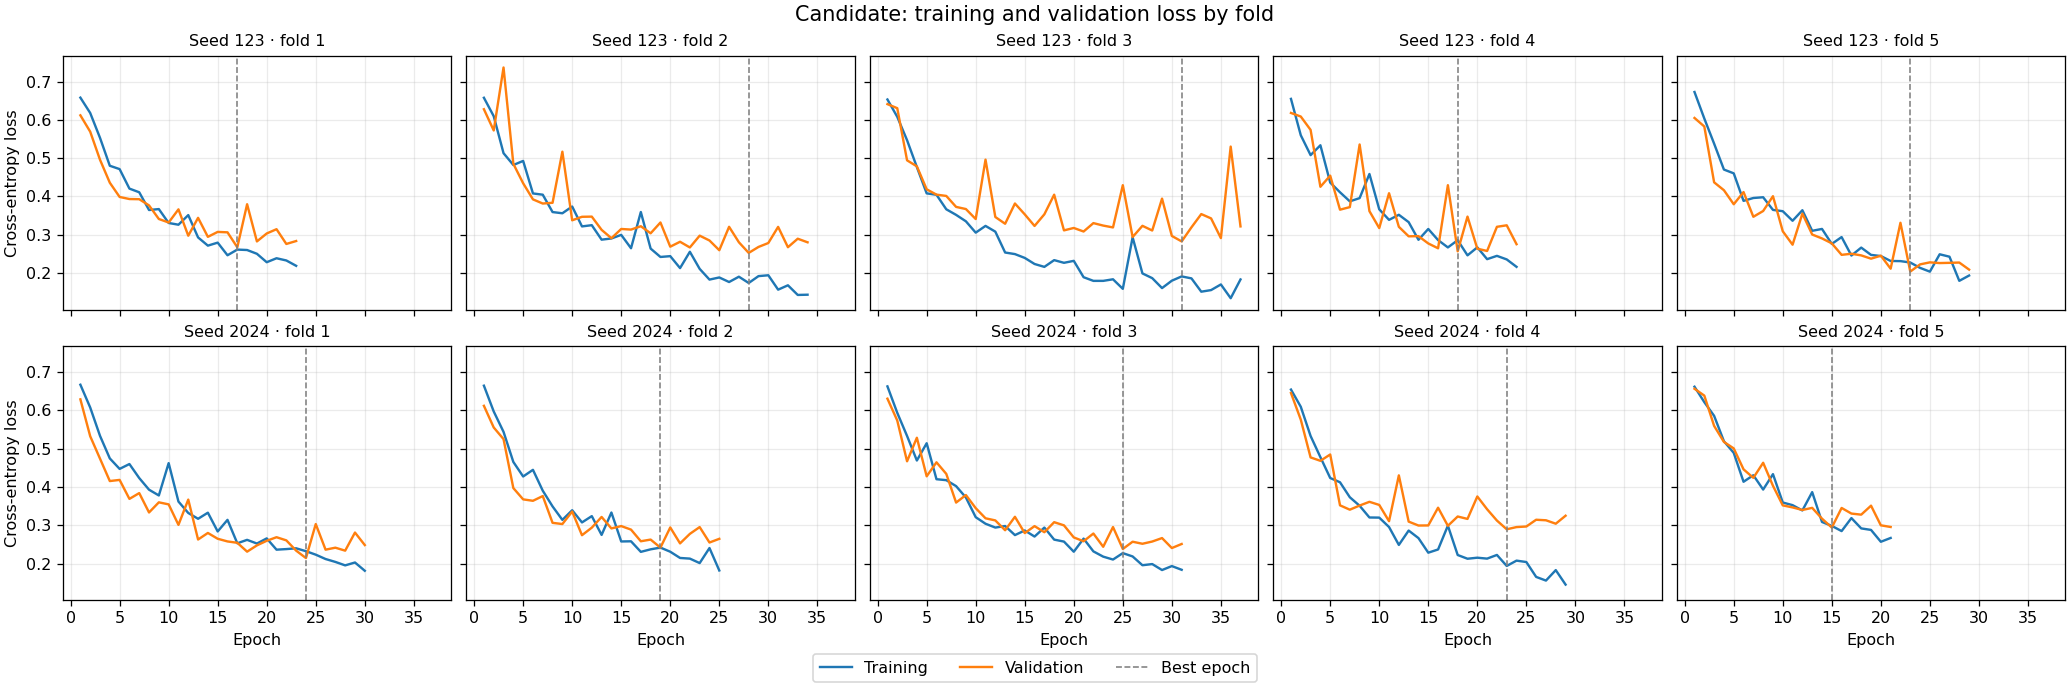

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True, constrained_layout=True)
for row, seed in enumerate((123, 2024)):
    for col in range(5):
        result = candidate_histories[(seed, col + 1)]
        epochs = range(1, len(result["train_losses"]) + 1)
        ax = axes[row, col]
        ax.plot(epochs, result["train_losses"], label="Training", color="tab:blue")
        ax.plot(epochs, result["val_losses"], label="Validation", color="tab:orange")
        ax.axvline(result["best_epoch"], color="gray", linestyle="--", linewidth=1, label="Best epoch")
        ax.set_title(f"Seed {seed} · fold {col + 1}", fontsize=10)
        ax.grid(alpha=0.25)
        if row == 1:
            ax.set_xlabel("Epoch")
        if col == 0:
            ax.set_ylabel("Cross-entropy loss")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
fig.suptitle("Candidate: training and validation loss by fold", fontsize=13)
plt.show()


### Fold log loss across split seeds

Fold numbers from different split seeds refer to different validation samples; lines help visualize variation.


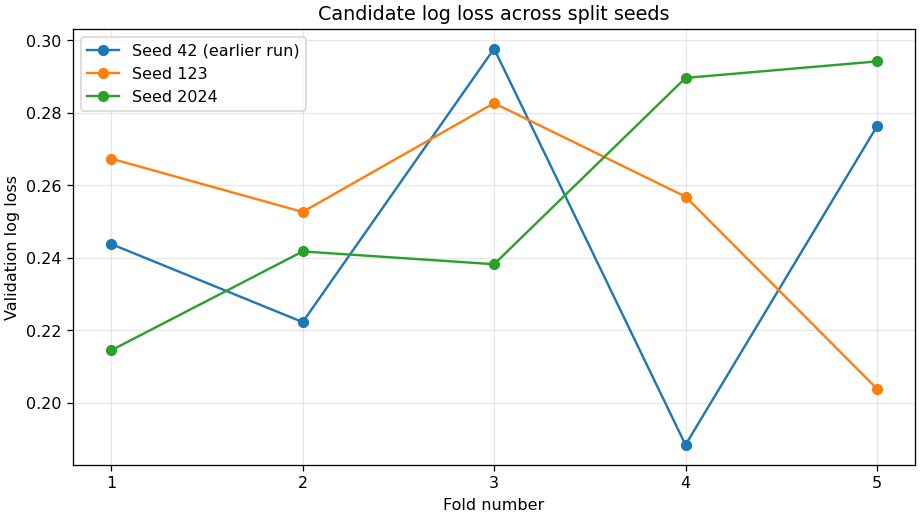

In [ ]:
# Seed 42 values are the six-decimal fold scores saved in experiment 7 above.
seed42_fold_log_loss = [0.243717, 0.222183, 0.297617, 0.188324, 0.276179]
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(range(1, 6), seed42_fold_log_loss, marker="o", label="Seed 42 (earlier run)")
for seed in (123, 2024):
    rows = candidate_df[candidate_df["split_seed"] == seed].sort_values("fold")
    ax.plot(rows["fold"], rows["log_loss"], marker="o", label=f"Seed {seed}")
ax.set(xticks=range(1, 6), xlabel="Fold number", ylabel="Validation log loss",
       title="Candidate log loss across split seeds")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


### Observed results

| Split seed | Mean fold log loss | Fold log-loss SD | Mean accuracy |
| --- | ---: | ---: | ---: |
| 42 (earlier candidate-selection run) | 0.2456 | 0.0432 | 89.96% |
| 123 | 0.2526 | 0.0296 | 89.28% |
| 2024 | 0.2556 | 0.0348 | 89.03% |

The candidate's mean log loss remains close to 0.25 across these three splits, while individual folds vary. This is a stability check of the selected candidate; the original reference was not rerun on the new splits in this section, so these results do not establish a fresh paired advantage over it. Training and validation curves show varying gaps across folds. Early stopping and selection on the validation folds can make scores optimistic; repeated splits overlap, and the training seed was fixed. The training histories for seeds 123 and 2024 were recorded in the separate GPU run above; seed 42 retains its earlier fold scores only.


## Matched comparison: two vs three convolution blocks

The 04 baseline and 05 candidate use identical seed-123/2024 stratified splits, dropout 0.5, AdamW weight decay 1e-4, learning rate 0.001, augmentation, training seed and early stopping. The 04 histories are the new weight-decay run appended to `04_Cross_Validation.ipynb`; the 05 histories are the saved candidate runs above. Both arrays below are snapshots of those measured per-epoch GPU histories, so the plots do not require training or loading another notebook.

The candidate adds a 32-to-64 convolution and pooling block; that pooling also changes the flattened classifier size and total parameter count. These are comparisons of complete architectures. Solid lines show validation loss; dashed lines show training loss. Axes are shared across all folds in each figure. Different models can consume random numbers differently despite the same training seed. Training loss is measured with augmentation and dropout active, while validation uses evaluation mode. Validation folds choose checkpoints and inform model selection, and repeated folds overlap; this is an exploratory comparison, not an independent final test.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Full-precision saved measurements; these do not retrain either model.
comparison_04_histories = {(123, 1): {'best_epoch': 28, 'log_loss': 0.3102436363697052, 'accuracy': 0.881619937694704, 'train_losses': [0.6759275709709337, 0.6196803848258425, 0.5808271215655147, 0.5330412260322764, 0.508449756857574, 0.49945052489580255, 0.49441886995792017, 0.42894252944252775, 0.4272693108741139, 0.3918496220142509, 0.3703145794309124, 0.3555876790826802, 0.34154297642566595, 0.337656015479416, 0.3033461761185413, 0.31354186802032524, 0.3139062944483172, 0.28950106465807207, 0.3453809608555082, 0.26210344462587976, 0.2865039823360491, 0.254126827278271, 0.23393432928985297, 0.22306754266435247, 0.22168659444953534, 0.21972106852432943, 0.22137108189652696, 0.19517604557220952, 0.17381536266066, 0.17796981012243968, 0.16012356591440696, 0.2140993538979711, 0.1407117028245216, 0.16124725299840176], 'val_losses': [0.6036864537687688, 0.5672766150343826, 0.5614483547730609, 0.4739205775973953, 0.5152595288169532, 0.49763305666290714, 0.422321119551718, 0.411546084136235, 0.39816624140860135, 0.3875445124005603, 0.4011923541718183, 0.3773574478158327, 0.401336376158509, 0.35415354612460387, 0.3576012054556905, 0.37713808695150314, 0.3481352249874133, 0.42878863897763564, 0.3295258287328797, 0.3560338013129442, 0.3366909209244255, 0.3312669531159347, 0.3203073173929644, 0.34852700411832405, 0.32850277469336775, 0.35189715115864095, 0.3198760711410985, 0.3102436482246655, 0.3631044796314758, 0.3318465774910774, 0.33581440976089755, 0.3112416820501984, 0.36636296508839566, 0.32143802241845826]}, (123, 2): {'best_epoch': 15, 'log_loss': 0.348868727684021, 'accuracy': 0.8566978193146417, 'train_losses': [0.6810960312049461, 0.6176698779743905, 0.5800587815738524, 0.5412782084542331, 0.4870552620846874, 0.4743090184145576, 0.43440747813888575, 0.40493175468682685, 0.3850075071060555, 0.3638695344177894, 0.31847841272875377, 0.3232354233251915, 0.3405831022564081, 0.30121970159856026, 0.2526313707316679, 0.26962457958460784, 0.27698668098877116, 0.2814099856957921, 0.2363671590853555, 0.23314034079353232, 0.21316337281154266], 'val_losses': [0.625391674561664, 0.5869022923466573, 0.5656007563585062, 0.5075992002758282, 0.4755421815515493, 0.5074793166739175, 0.4497771741384626, 0.41435273634915376, 0.3964831187798514, 0.3923741236656474, 0.36979823356838476, 0.37562998209811505, 0.38303587521169613, 0.35365995173376075, 0.34886872136739044, 0.4467333566362612, 0.4022389750613211, 0.3786171396202002, 0.3572845080172408, 0.3673720051566148, 0.40927114553540667]}, (123, 3): {'best_epoch': 18, 'log_loss': 0.33939844369888306, 'accuracy': 0.8442367601246106, 'train_losses': [0.6641274311072364, 0.606726439967345, 0.5656114226194071, 0.5371183083100144, 0.4959260395561822, 0.425966631850505, 0.39074625712489114, 0.4058521174631914, 0.3756173046440792, 0.33500698841934035, 0.3427338646615936, 0.3452156531281148, 0.3169988536988026, 0.2759163562710733, 0.2866992242314903, 0.25412099086334716, 0.2604732499606704, 0.22063111402936403, 0.23318053386555238, 0.21274657280925466, 0.19372701375445442, 0.2002415015933482, 0.21072241102235678, 0.17753037782451275], 'val_losses': [0.6445231277994649, 0.6076493162975133, 0.5940981275196016, 0.5384459469548638, 0.48635980542575086, 0.46412227012658047, 0.4603159305091216, 0.5098497358809378, 0.42073627721483464, 0.39345881556424767, 0.41395972729471986, 0.37686356075827576, 0.4130647134186694, 0.37537444533774417, 0.3611658074402735, 0.4172753821652255, 0.35328402586072405, 0.3393984367821447, 0.38526569404334665, 0.36038138914702467, 0.35909378199005426, 0.3908862297037309, 0.412510921673797, 0.363977827387064]}, (123, 4): {'best_epoch': 19, 'log_loss': 0.28207382559776306, 'accuracy': 0.8691588785046729, 'train_losses': [0.6611681735710715, 0.6012951871982702, 0.5573576488071182, 0.5143551163996744, 0.4932970359329126, 0.44179805899539776, 0.4150735937517691, 0.41769480324311825, 0.3836814572545391, 0.41503001741385515, 0.35495515455748083, 0.3234034456597207, 0.31776311457888834, 0.3030707957869104, 0.2793068095797779, 0.27695378844661817, 0.29755517901360573, 0.2730757291207347, 0.22856731629195107, 0.2538949598791259, 0.2127572914305276, 0.2443154885819064, 0.1983394497005227, 0.18220263675424334, 0.18705163007008313], 'val_losses': [0.6345705076170116, 0.572074073404538, 0.518912284916435, 0.5153568286297848, 0.4589723969731375, 0.4163563308129058, 0.4142414225596134, 0.41965201225514726, 0.42140217432955346, 0.3609202802181244, 0.33354268044326163, 0.3557293980478126, 0.30977153290655013, 0.32282358189795246, 0.3067147631642069, 0.30072599558327984, 0.303650811627925, 0.2977338700186798, 0.28207385679852, 0.28740822444916514, 0.3255105905722235, 0.2955115428426509, 0.2922428201661355, 0.2922711590003234, 0.32268346900648415]}, (123, 5): {'best_epoch': 26, 'log_loss': 0.2740429937839508, 'accuracy': 0.896875, 'train_losses': [0.6875508702432627, 0.6250407413530201, 0.5823020255454233, 0.5190451236157403, 0.47458938757578534, 0.42233457799269775, 0.39985727019770495, 0.39160127784604226, 0.377388648897688, 0.3836053806673329, 0.3720710273843688, 0.35324932676609433, 0.3228761853876515, 0.28896279581982026, 0.28621639418082073, 0.2746431701279875, 0.2644087532274077, 0.23888991944886442, 0.23402725721816778, 0.24399921531292879, 0.22472593487701684, 0.2120117038790125, 0.17059664637128882, 0.18030280044238514, 0.1832865255644017, 0.21305493402332532, 0.18377320995304816, 0.171152022583091, 0.16105207269344002, 0.13688555457324625, 0.14792487625543296, 0.10544128750807771], 'val_losses': [0.615203458070755, 0.5600404411554336, 0.5154225856065751, 0.46257883310317993, 0.4200045943260193, 0.39801347255706787, 0.41209161281585693, 0.3522783577442169, 0.41984806060791013, 0.44140741527080535, 0.394417929649353, 0.3297373026609421, 0.32266730070114136, 0.2939877942204475, 0.2985956698656082, 0.27820328176021575, 0.3655483901500702, 0.2968397006392479, 0.2948307543992996, 0.2775947690010071, 0.2939717799425125, 0.3090301275253296, 0.28795825093984606, 0.2868517473340034, 0.28998241424560545, 0.2740429684519768, 0.32954998314380646, 0.315111044049263, 0.29818131774663925, 0.31098620891571044, 0.2912418834865093, 0.33492756485939024]}, (2024, 1): {'best_epoch': 22, 'log_loss': 0.3077559769153595, 'accuracy': 0.8785046728971962, 'train_losses': [0.7089852619617132, 0.6510208106003789, 0.6237618208210262, 0.6007521501157959, 0.5712080004153917, 0.5349213846103344, 0.4945010254370079, 0.4752382132009148, 0.44840592670886664, 0.40942111983024226, 0.3989675242340574, 0.3995486568000432, 0.35451608501368914, 0.3642209000124749, 0.3785397863583182, 0.32701515683371485, 0.3098429056786041, 0.3206142314643667, 0.3105754219547251, 0.29132241475673876, 0.28655956266847143, 0.2854119241005354, 0.2562463015480517, 0.2354708547970325, 0.24576419827093487, 0.22980203955134468, 0.23573266718876335, 0.23341643224910935], 'val_losses': [0.6389473431578306, 0.5952835936226949, 0.5745017236313344, 0.5551635934231437, 0.5227453465286259, 0.44753590218049716, 0.41977638662995836, 0.41061543360551256, 0.4024167765654798, 0.3696864422609648, 0.38393632716602993, 0.36581745065491744, 0.3536535706951332, 0.3361847289243852, 0.3618828733212306, 0.343797586417077, 0.31555630037772947, 0.33450032171786404, 0.3135329882300474, 0.3084990610583967, 0.3204568650365096, 0.3077559207454087, 0.41776480927274234, 0.3401016152907755, 0.3601793800930368, 0.4157936729003336, 0.35142387853578827, 0.3402150887937932]}, (2024, 2): {'best_epoch': 26, 'log_loss': 0.2764114439487457, 'accuracy': 0.881619937694704, 'train_losses': [0.7142455511881054, 0.6499576817149774, 0.6127567072446144, 0.5783033063889294, 0.5335747764989536, 0.5453646520525798, 0.47541309246214125, 0.4489001744860146, 0.4396606462594595, 0.43297734988137604, 0.4217580771037404, 0.3939176322609209, 0.4150861211219804, 0.35053651703816324, 0.35375660820483046, 0.3155811761773757, 0.3206861999266239, 0.3238879722330374, 0.30191902434602175, 0.2860302884111345, 0.27643726064605073, 0.26637470399320634, 0.24895301921436866, 0.22198827783646105, 0.24531363794000838, 0.22713324532133475, 0.22597098283161898, 0.3391991130287584, 0.22263965532125576, 0.22995066599207564, 0.19651326577491995, 0.18409129956887602], 'val_losses': [0.6259071590187394, 0.603096217659775, 0.5572127237498203, 0.5205631984914203, 0.518387129698587, 0.4781364022849876, 0.4327490687184616, 0.4025438632641997, 0.4283302639875085, 0.3884853524303882, 0.3593352776937581, 0.39266214642754965, 0.3549611288996129, 0.3128213245897464, 0.33266850507519324, 0.3133438308650738, 0.30606332772942346, 0.3510863156147835, 0.31952250486593753, 0.36044310850912353, 0.28360703930757775, 0.3159095947108467, 0.2963769151553558, 0.28639893010084594, 0.31670575223955966, 0.2764114231666161, 0.33458310139809394, 0.3121552005920826, 0.3045155583196131, 0.277224349631925, 0.29411310926108764, 0.30529264535905787]}, (2024, 3): {'best_epoch': 22, 'log_loss': 0.31404903531074524, 'accuracy': 0.8660436137071651, 'train_losses': [0.6824936707411905, 0.6260081612775777, 0.5932927082175866, 0.5552755949883748, 0.5164277140088873, 0.5013306751463995, 0.45444732142535393, 0.4506326594672348, 0.43941651892123146, 0.37854107468739584, 0.42278563540751174, 0.37542238804807165, 0.3666843292031173, 0.36643625551940684, 0.33989082775075086, 0.31292530645733224, 0.3237519437971286, 0.35413549620939805, 0.3220632705671984, 0.29344564938187506, 0.2756014437249928, 0.2617824014656635, 0.2609703199108968, 0.2771449732947703, 0.2802084703245204, 0.25205801595191146, 0.22754095233425162, 0.22996873058384504], 'val_losses': [0.6226981792865884, 0.597153500604481, 0.5705308834340342, 0.5465050389833539, 0.4828525348987163, 0.4510181939861856, 0.46587067229725493, 0.41356608188040905, 0.40316746743668647, 0.44517411435504567, 0.3850913719967518, 0.404557390469257, 0.36413020963238035, 0.3473886960763426, 0.3414315052121599, 0.3849501984884434, 0.3399883595953849, 0.34056649902527947, 0.32770093653432303, 0.3181042479948834, 0.3264346653798659, 0.31404900476568587, 0.3370520270130716, 0.331520388802264, 0.3217579897876098, 0.36395604625297856, 0.3353553774572236, 0.3312022791844662]}, (2024, 4): {'best_epoch': 32, 'log_loss': 0.2996966242790222, 'accuracy': 0.8909657320872274, 'train_losses': [0.6805944371669439, 0.6251962579328012, 0.6034904842439891, 0.5574246890732578, 0.5261990283488855, 0.5200314664877864, 0.48270202630772224, 0.451994667690616, 0.4221057753403114, 0.3990500799655357, 0.39382414141160293, 0.37329779187869205, 0.3703439078545626, 0.3661583371443016, 0.3095523935574995, 0.3262491627586882, 0.31115119899343624, 0.30426972920970813, 0.37510315870644056, 0.2899366851114985, 0.29015653912015754, 0.28232980262276164, 0.2735997988019989, 0.24365623387640933, 0.2789626774012996, 0.26609288993424396, 0.22467142092379788, 0.23209228700524834, 0.2275229088398784, 0.22490397110778843, 0.21472112291484538, 0.2040643270184821, 0.18636812479906684, 0.19532709170803603, 0.19269459100551933, 0.22082085455662556, 0.2210626869762979, 0.1714618463513448], 'val_losses': [0.6533376045316179, 0.617692404818312, 0.5777307202882855, 0.5428708316381103, 0.4900817648272648, 0.5157030562745448, 0.4843292097064936, 0.42062247802163955, 0.4081668187153302, 0.38978728902674165, 0.42855495455851805, 0.3437279013458442, 0.34933880853504407, 0.33722721360554203, 0.3209323754934507, 0.377746721480123, 0.3104135108142627, 0.3258788563380732, 0.39441457827143206, 0.32123442713716693, 0.35005554826088786, 0.30779148949269564, 0.32044966105731476, 0.35617832936973215, 0.3138126961167356, 0.3403680898318781, 0.3037473467465873, 0.3956119508665299, 0.31697061602200305, 0.33030459168729753, 0.3261906865786912, 0.29969660459649156, 0.30578581622085094, 0.3115713531354506, 0.3111567644872398, 0.38768112696591195, 0.30501496271923695, 0.3362598634583185]}, (2024, 5): {'best_epoch': 25, 'log_loss': 0.32067397236824036, 'accuracy': 0.846875, 'train_losses': [0.6667362644664967, 0.6114207171948156, 0.5729663515016669, 0.5379580973279068, 0.5020082832496857, 0.45732928046556276, 0.4501202468560121, 0.41081005474117316, 0.38900053538266, 0.3989556990679922, 0.38145977500071776, 0.3704792788466932, 0.33308762636882866, 0.33694130256539934, 0.32337053929712345, 0.29015398118354824, 0.2931083347010093, 0.28133542255449145, 0.2797815865631044, 0.24992320846731417, 0.2571846698860513, 0.2702131869265595, 0.2584322440754216, 0.2250151276774124, 0.2203483668814567, 0.22036428215719087, 0.18649661007142884, 0.1777444767107102, 0.19250227849802867, 0.18556663863987566, 0.1626338285634822], 'val_losses': [0.6488839447498321, 0.6428017437458038, 0.5750866442918777, 0.5484023034572602, 0.5055502623319625, 0.46599174439907076, 0.47449253499507904, 0.4620289832353592, 0.4102199971675873, 0.4408851832151413, 0.4182926282286644, 0.3949157476425171, 0.4017189770936966, 0.36057120859622954, 0.38711252212524416, 0.3779800832271576, 0.3762449577450752, 0.36561665385961534, 0.3359565556049347, 0.32455388009548186, 0.38077298551797867, 0.35349041223526, 0.3907238274812698, 0.330154775083065, 0.32067396193742753, 0.32830901592969897, 0.3427437454462051, 0.4466760069131851, 0.5169437080621719, 0.3860244646668434, 0.351411896944046]}}
comparison_05_histories = {(123, 1): {'best_epoch': 17, 'log_loss': 0.26727133989334106, 'accuracy': 0.897196261682243, 'train_losses': [0.6580651191557559, 0.618046596611466, 0.5530936519614627, 0.48019870179571034, 0.4714175513593461, 0.42050147326031606, 0.4109160890824518, 0.36461624026948924, 0.3670311814532648, 0.33071790100166043, 0.3262042001438554, 0.35131472540222286, 0.29302743541850584, 0.2715634073211361, 0.27939752576435717, 0.24642952237734084, 0.26124716548369625, 0.2601128748544751, 0.25027926637161746, 0.22825600650337172, 0.2386272880869365, 0.23280139015994775, 0.2188588124834181], 'val_losses': [0.6118798638429969, 0.5691798301500695, 0.4958921051888822, 0.43590561722512605, 0.39869112672278445, 0.3932683287475641, 0.39282041068719786, 0.3766071387070501, 0.34113684719982573, 0.33197654109169666, 0.36631985119002874, 0.29748519382372823, 0.34416102570324925, 0.29453403827940283, 0.307396342941615, 0.30631652603874626, 0.267271318098652, 0.37965306853208214, 0.28256968986765246, 0.3033220652850617, 0.31449955963526743, 0.27595644924104956, 0.2835903705280518]}, (123, 2): {'best_epoch': 28, 'log_loss': 0.2525767385959625, 'accuracy': 0.8909657320872274, 'train_losses': [0.657726875804684, 0.6096207774530977, 0.5130390984326345, 0.4821642156884899, 0.49280547761210963, 0.40788711308387693, 0.40457574301925564, 0.35926892894696927, 0.3560959212231542, 0.37370820804582566, 0.32177166868399015, 0.3249723865060442, 0.2871501863885465, 0.29029187906187953, 0.2996806169301852, 0.2647554114844217, 0.3594181202685958, 0.26386012427874683, 0.24199569926452724, 0.24410116816533328, 0.21289367361730277, 0.25554538057102233, 0.21087065283920461, 0.1828868312359042, 0.18845751711885306, 0.17654570765264874, 0.1904274396931706, 0.17401579013116084, 0.19196662369502865, 0.1941855413373197, 0.156593049050324, 0.1679838259856123, 0.14278494094266894, 0.14341022147247545], 'val_losses': [0.6278008582807404, 0.5723546810239275, 0.7368080036553424, 0.4853262739644801, 0.43449729271349136, 0.392401556287837, 0.3815062252537716, 0.3834723570091052, 0.5169172624930461, 0.3377627961343369, 0.3468949397615334, 0.34733878545219377, 0.31279296337299023, 0.2909464090114178, 0.31508110050580573, 0.3134921493314822, 0.3222206155281743, 0.3037697787823103, 0.331996771596906, 0.2688291138800995, 0.28167774952908925, 0.26681430858345573, 0.2976260666503909, 0.2850012248149414, 0.25959499745529635, 0.3207511716169574, 0.28034523083041635, 0.2525766972802589, 0.26817222057846796, 0.27838873937493913, 0.32052476755181253, 0.2674620218366074, 0.28963490215788323, 0.2802807088952941]}, (123, 3): {'best_epoch': 31, 'log_loss': 0.2825908660888672, 'accuracy': 0.8722741433021807, 'train_losses': [0.6532345899175316, 0.6080062538036962, 0.5469293100519842, 0.47673862512838255, 0.4080637695728014, 0.40439728750257126, 0.36647697354050607, 0.3519056893751571, 0.3350930818104688, 0.3055019591668576, 0.32309755387941747, 0.30809516948375587, 0.2535878264012043, 0.2494544131813436, 0.23950155538130066, 0.22364480219729135, 0.21607772079285523, 0.2337075668421232, 0.22670394545733139, 0.23182921451157132, 0.18910089277880832, 0.17954161671438165, 0.17955244307508597, 0.18366554647753783, 0.15874088630486724, 0.29339667069359116, 0.19901240125170744, 0.18667191353830526, 0.16068935359171965, 0.1800291815123703, 0.19119637066372094, 0.18604603585978027, 0.15130475758112508, 0.1554709004175821, 0.17020764276501452, 0.13427563276452564, 0.18323704599172735], 'val_losses': [0.6411315425534114, 0.63051641544449, 0.49436218771979074, 0.47860195462206073, 0.41866987330891264, 0.4047257179783141, 0.40135420872786337, 0.37273347767714027, 0.36712011889876606, 0.3410132172694459, 0.4961698259520011, 0.3463551218264571, 0.3286885266363435, 0.38158421278742616, 0.35327278565023545, 0.3229380964861481, 0.3534047540474532, 0.40462755896963437, 0.31142235136477747, 0.317706734034874, 0.3084552687276561, 0.3303973465879387, 0.3239472565992599, 0.31910732379212187, 0.42940078030494144, 0.29402312125743735, 0.32332234590595754, 0.3110515280304668, 0.39439783660793604, 0.29686232101508764, 0.28259087314486875, 0.31940713729071096, 0.3539739628075811, 0.3427148330898671, 0.2912218069361749, 0.5302483032796984, 0.3218133557251309]}, (123, 4): {'best_epoch': 18, 'log_loss': 0.2567932903766632, 'accuracy': 0.8940809968847352, 'train_losses': [0.6548392953393242, 0.5598623055503039, 0.5079319929110289, 0.5337228765965252, 0.43628486281874956, 0.4108839189098017, 0.38723660542085964, 0.3956737823999216, 0.4587071607185532, 0.36644607400253054, 0.3388658208643331, 0.35214348691381336, 0.33291423572800816, 0.28685544536899793, 0.3150807932448963, 0.2860661677127691, 0.26689546761434707, 0.2858188164530036, 0.24619698683010444, 0.26706727418180376, 0.23624530585594505, 0.24487028369100783, 0.2355337253744864, 0.21617026391583594], 'val_losses': [0.6181140380485035, 0.6087240548891442, 0.5738530565645094, 0.42528944070279784, 0.45425665332149495, 0.36547965384625203, 0.37218324380500295, 0.535735492387096, 0.36167527380112174, 0.3173747403413707, 0.40846909745088616, 0.3207221441319056, 0.2959082167235862, 0.2963540988373701, 0.27728928517944806, 0.2646232718540895, 0.42942032314013007, 0.2567932833438722, 0.34739776798219324, 0.2635924662738992, 0.25763623158931964, 0.32073827252139026, 0.3246611570228599, 0.27534957202374455]}, (123, 5): {'best_epoch': 23, 'log_loss': 0.20381192862987518, 'accuracy': 0.909375, 'train_losses': [0.6727800900319655, 0.6035310624173126, 0.5379035990928935, 0.4702517495162762, 0.46036923934366103, 0.38848121663863044, 0.39598238143222725, 0.3979226171598999, 0.36490845708089453, 0.3615200513062819, 0.33651022784806484, 0.3640439562598168, 0.3103039517209537, 0.3151589031345748, 0.27607517162587414, 0.2939577981876064, 0.2456890014000237, 0.2664386849165705, 0.24740021065388143, 0.24436312902289387, 0.2315254794623024, 0.2311272311062085, 0.22749262119750738, 0.2134995485577628, 0.2036096602678299, 0.24900142323933658, 0.24265562197501042, 0.17962462526986903, 0.19348746946667586], 'val_losses': [0.6050025045871734, 0.582734489440918, 0.43690299689769746, 0.4162944585084915, 0.3796579897403717, 0.4114797204732895, 0.34690660834312437, 0.3620032608509064, 0.4006753176450729, 0.3090633198618889, 0.2739932909607887, 0.3552203804254532, 0.30058651715517043, 0.2903830587863922, 0.27753220647573473, 0.24752197265625, 0.2503469601273537, 0.24606776982545853, 0.23750499486923218, 0.24530154913663865, 0.21139595210552214, 0.33124660551548, 0.2038119062781334, 0.22257978543639184, 0.22787900567054747, 0.2260525643825531, 0.22665461003780366, 0.2273764818906784, 0.20894363299012184]}, (2024, 1): {'best_epoch': 24, 'log_loss': 0.2144031524658203, 'accuracy': 0.9190031152647975, 'train_losses': [0.6670945051212563, 0.6076584949868783, 0.5336095892816247, 0.47465847611473766, 0.4472801894855425, 0.4599412213473792, 0.42335338587419, 0.39294919517945237, 0.3778940446657402, 0.4623706831610584, 0.36195308894546163, 0.33217545939625376, 0.3169536579426433, 0.33289645190640343, 0.28390384266270574, 0.31415891421440517, 0.2529941495313416, 0.26194138018244156, 0.2523415167398594, 0.2657493623096963, 0.23630068048149555, 0.23784142989296517, 0.23987506828267224, 0.23235385814450815, 0.22325038580065673, 0.21189145342626886, 0.2043102330971721, 0.19528744564575323, 0.20281073380684855, 0.18123383930392872], 'val_losses': [0.6288825028410582, 0.5326202623430071, 0.474072563174729, 0.41551896443661607, 0.41851211747160394, 0.36894487739890425, 0.3840651259724213, 0.3334862165828671, 0.35994643061146187, 0.354606970899515, 0.3010999981808618, 0.3670921013734019, 0.2628347613727213, 0.2799406447917487, 0.2648227109921577, 0.25782466808847526, 0.254277994692994, 0.23111548451182717, 0.24751892883868779, 0.2595158625980988, 0.2688560259304561, 0.260588211797549, 0.23379988347073563, 0.21440315276442923, 0.30322792151263933, 0.23632826924955436, 0.24149373349728392, 0.23373242968046382, 0.2809889413113374, 0.24835362724038773]}, (2024, 2): {'best_epoch': 19, 'log_loss': 0.24167928099632263, 'accuracy': 0.897196261682243, 'train_losses': [0.6645890748417201, 0.597266768628698, 0.544000272314621, 0.46542349087824975, 0.42744524982508886, 0.44485059823036566, 0.39034859240287373, 0.34929578420898455, 0.3140900811362037, 0.33932324953592113, 0.30747021239944855, 0.3239365289871895, 0.27486706453659343, 0.3333327551884105, 0.25775618974296544, 0.25817917009186947, 0.23060459990289559, 0.23720621146876525, 0.2417598181605246, 0.2309388250275134, 0.2146664628597878, 0.21294761822861638, 0.2012864223689375, 0.2406000786708466, 0.1819880442114566], 'val_losses': [0.6119968415792114, 0.5554674021737226, 0.5250401348339806, 0.3971860268591349, 0.36767988589322453, 0.363952616061377, 0.3763645154850505, 0.3063972169690043, 0.303235979141476, 0.3358405669715917, 0.27413448591562817, 0.29382254408434544, 0.321768648643917, 0.29181319746737167, 0.29793531292718706, 0.28869228334256053, 0.25829698057334605, 0.2626725970810958, 0.24167927884644716, 0.294331623586562, 0.2527270588503042, 0.2775796871005653, 0.2953249206331289, 0.25501491506859614, 0.2646034625126774]}, (2024, 3): {'best_epoch': 25, 'log_loss': 0.2381552755832672, 'accuracy': 0.9065420560747663, 'train_losses': [0.6627581722552388, 0.593803440000708, 0.5333194144285013, 0.4691818960922729, 0.514268530571916, 0.4203257215088081, 0.41782009740964754, 0.4022494466250889, 0.3725413292623179, 0.32117814197265254, 0.30402955565012163, 0.2940410670134023, 0.2980629359477215, 0.27439940839843274, 0.28649417622797396, 0.270564313220123, 0.2940017623029829, 0.26256711963369617, 0.2574053635865752, 0.230925872747729, 0.2651663276244213, 0.2318280061499295, 0.21811420199281986, 0.21050610590148325, 0.2273007412720544, 0.21861039587761266, 0.19567650477587015, 0.19870690781904773, 0.18313684140506076, 0.19343343411956276, 0.1837601803609011], 'val_losses': [0.6306497463927462, 0.5735970234202448, 0.4671360122451901, 0.5286121970025178, 0.4279155935453849, 0.4644730213646577, 0.43423102057982826, 0.359316574821591, 0.37897400692615923, 0.3447803492858031, 0.3182696224744446, 0.31272195692745697, 0.28703260663142455, 0.32215172163793976, 0.2795959299784212, 0.29784329695122264, 0.2819017039095501, 0.308100878263931, 0.2998033696988661, 0.26832770382132487, 0.25831630761006913, 0.2784715164858976, 0.24387066980760044, 0.2953898993979362, 0.23815527883274162, 0.25706752809780037, 0.2517400924290452, 0.25756926180046297, 0.26661726702410854, 0.24057990433271056, 0.2511650024916153]}, (2024, 4): {'best_epoch': 23, 'log_loss': 0.28955063223838806, 'accuracy': 0.8660436137071651, 'train_losses': [0.6544513747223819, 0.6095201794467489, 0.5332605331927096, 0.4779187453880221, 0.4235232248960392, 0.4123160179387938, 0.3732393222773159, 0.35099720638985754, 0.32037063023120466, 0.32002882224080076, 0.2954483474412423, 0.24874486467015572, 0.2862300587990789, 0.26651285805348207, 0.22843919233335525, 0.23681913135937668, 0.2990824904231847, 0.22238605477450094, 0.21264396451372983, 0.21533887875168378, 0.21294324537877077, 0.2225353569721488, 0.1938060044963566, 0.20769216210399163, 0.20402281303379746, 0.165152979641935, 0.15559913236604292, 0.18292158799404198, 0.14511290766351034], 'val_losses': [0.6454258811808078, 0.5759368945505018, 0.4772499172115623, 0.46837636094969753, 0.4848700186173864, 0.3521015268991298, 0.3407478295382681, 0.3515545428727646, 0.3612916317312888, 0.35316066847783384, 0.3106712384201656, 0.4303325448080758, 0.30956736086313597, 0.29937813642240385, 0.2995971084755158, 0.34591100232623445, 0.2986129243797231, 0.3229522094176937, 0.3166052244162634, 0.3752277907552749, 0.3418617146408818, 0.3123485674367887, 0.28955065089965537, 0.29532129092379894, 0.2968172083762576, 0.31447008632796575, 0.31308856132988616, 0.3041118190295971, 0.32496416345935003]}, (2024, 5): {'best_epoch': 15, 'log_loss': 0.2941083312034607, 'accuracy': 0.8625, 'train_losses': [0.6619258729096885, 0.6215928169054405, 0.5858313717946085, 0.519439116538128, 0.4891230918908045, 0.41368502471305874, 0.4307122917561516, 0.39329921252259586, 0.43357694371838434, 0.35950305435887747, 0.3525793106756478, 0.3387530020835615, 0.3865832838685342, 0.30861750050125836, 0.29837595181673116, 0.28485831172666815, 0.3188387922539355, 0.2918442718893568, 0.28789794728206325, 0.2569392055180214, 0.26689341696809016], 'val_losses': [0.65655517578125, 0.6386657595634461, 0.559572634100914, 0.5177366554737091, 0.500758945941925, 0.4461539089679718, 0.42389816641807554, 0.4632850021123886, 0.4031750649213791, 0.3520083069801331, 0.34666492193937304, 0.33999266028404235, 0.3455006003379822, 0.3173342883586884, 0.2941083639860153, 0.34525620341300967, 0.33059722781181333, 0.3277742713689804, 0.35122716426849365, 0.29990956634283067, 0.2955654218792915]}}


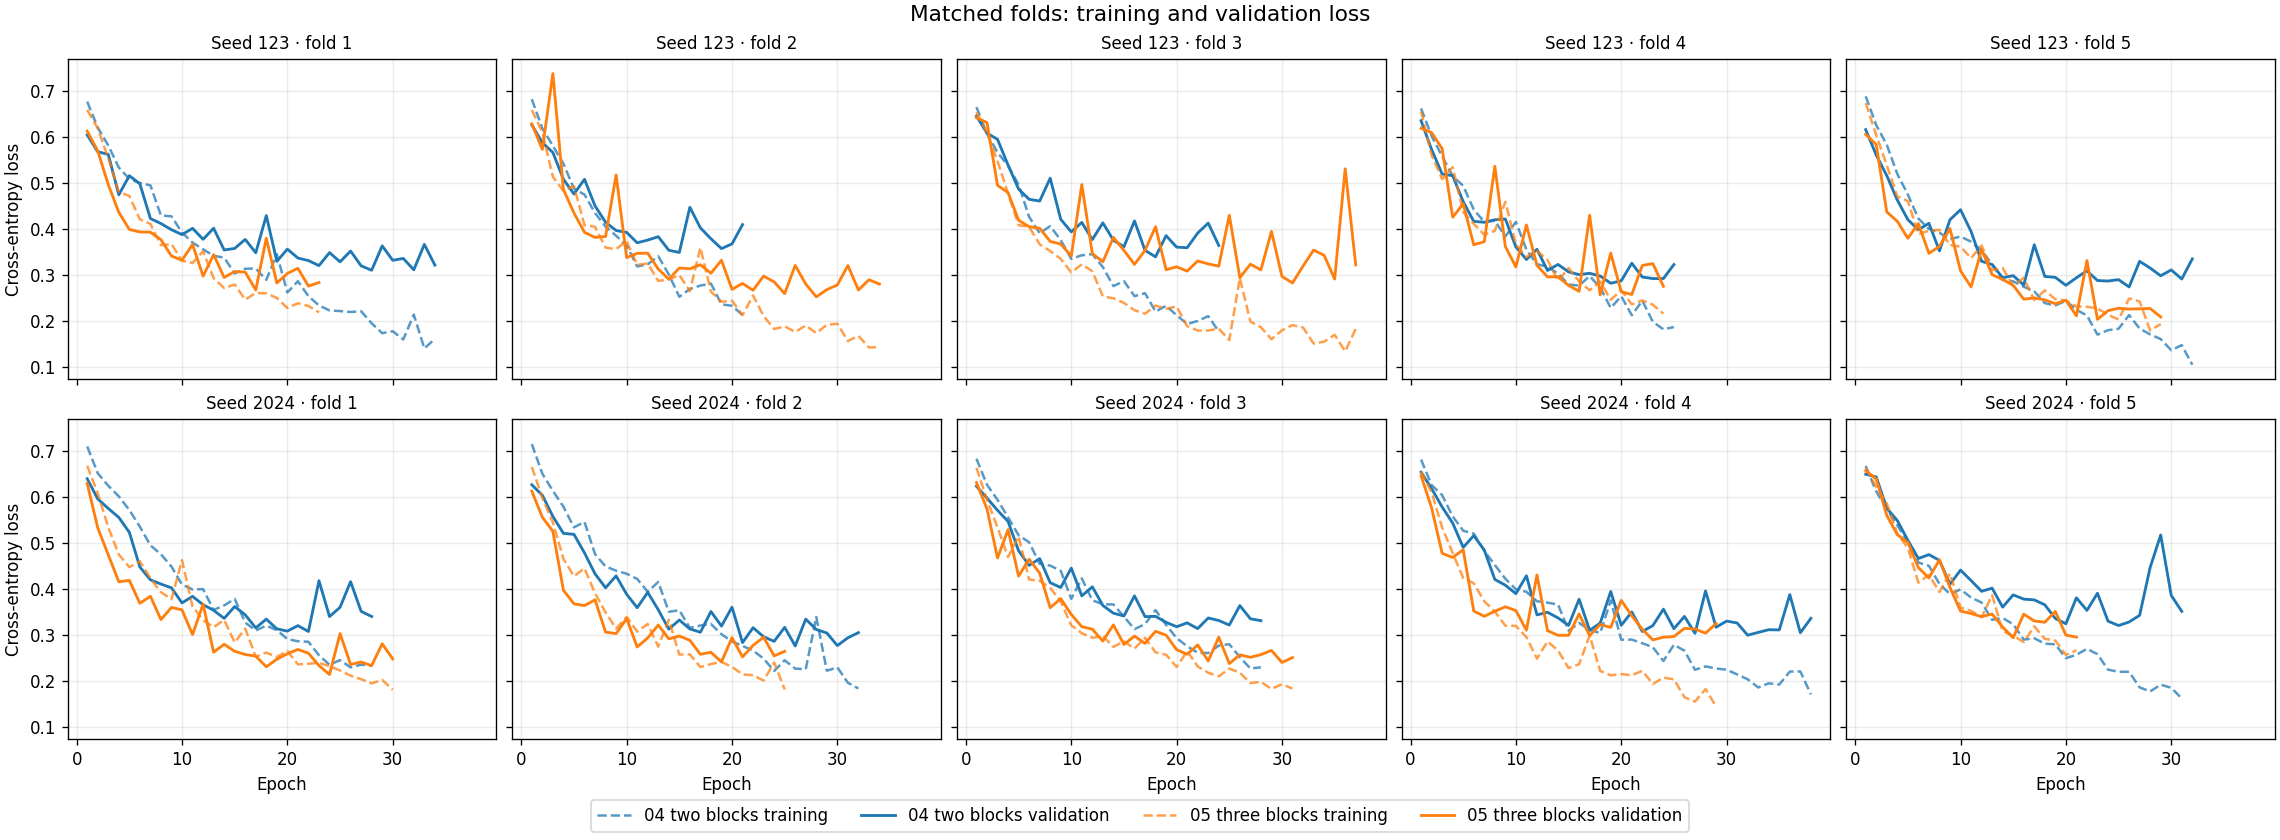

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(19, 7), sharex=True, sharey=True, constrained_layout=True)
for row, seed in enumerate((123, 2024)):
    for col in range(5):
        ax = axes[row, col]
        for history, color, name in ((comparison_04_histories, "tab:blue", "04 two blocks"),
                                     (comparison_05_histories, "tab:orange", "05 three blocks")):
            r = history[(seed, col + 1)]
            epochs = range(1, len(r["train_losses"]) + 1)
            ax.plot(epochs, r["train_losses"], color=color, linestyle="--", alpha=0.75, label=f"{name} training")
            ax.plot(epochs, r["val_losses"], color=color, linewidth=1.7, label=f"{name} validation")
        ax.set_title(f"Seed {seed} · fold {col+1}", fontsize=10)
        ax.grid(alpha=0.25)
        if row == 1: ax.set_xlabel("Epoch")
        if col == 0: ax.set_ylabel("Cross-entropy loss")
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4)
fig.suptitle("Matched folds: training and validation loss", fontsize=13)
plt.show()


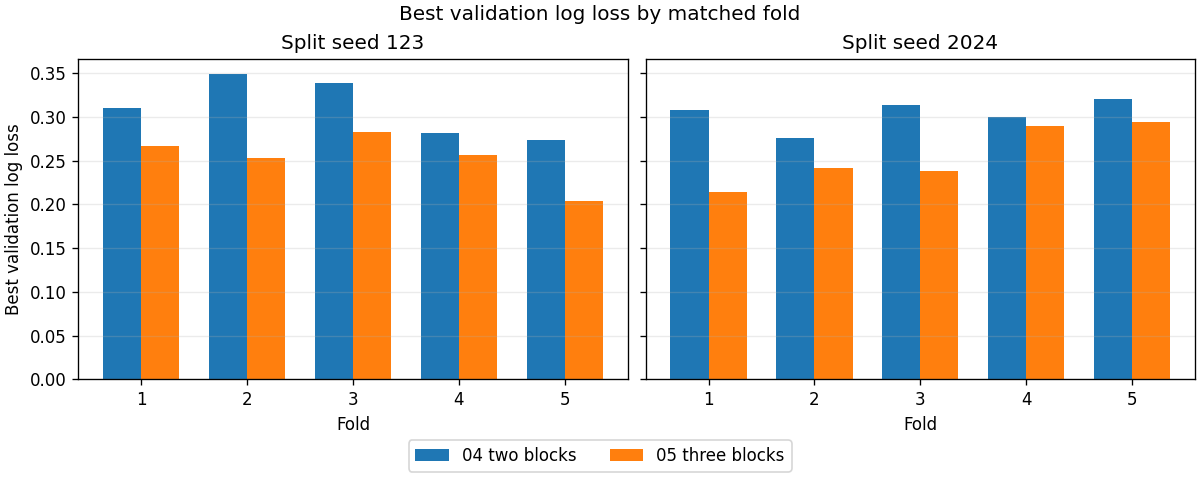

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)
for ax, seed in zip(axes, (123, 2024)):
    x = np.arange(1, 6)
    vals04 = [comparison_04_histories[(seed, f)]["log_loss"] for f in x]
    vals05 = [comparison_05_histories[(seed, f)]["log_loss"] for f in x]
    ax.bar(x - 0.18, vals04, width=0.36, label="04 two blocks", color="tab:blue")
    ax.bar(x + 0.18, vals05, width=0.36, label="05 three blocks", color="tab:orange")
    ax.set(xticks=x, xlabel="Fold", title=f"Split seed {seed}")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Best validation log loss")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle("Best validation log loss by matched fold")
plt.show()


### Recorded comparison

| Split seed | 04 mean log loss | 05 mean log loss | 04 mean accuracy | 05 mean accuracy |
| --- | ---: | ---: | ---: | ---: |
| 123 | 0.3109 | 0.2526 | 86.97% | 89.28% |
| 2024 | 0.3037 | 0.2556 | 87.28% | 89.03% |

In these runs the three-block candidate has lower mean log loss for both matched splits. The validation curves and bars show individual folds. The same validation folds select checkpoints and helped choose the candidate, the splits overlap, and one training seed was used, so this is evidence from these runs rather than a guaranteed improvement on unseen data.
